# Adversarial Search: Playing Dots and Boxes


## Instructions

Total Points: Undegraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play the game Dots and Boxes:

> "Dots and Boxes is a pencil-and-paper game for two players. The game starts with an empty grid of dots. Usually two players take turns adding a single horizontal or vertical line between two unjoined adjacent dots. A player who completes the fourth side of a 1x1 box earns one point and takes another turn. A point is typically recorded by placing a mark that identifies the player in the box, such as an initial. The game ends when no more lines can be placed. The winner is the player with the most points. The board may be of any size grid." (see [Dots and Boxes on Wikipedia](https://en.wikipedia.org/wiki/Dots_and_Boxes))

You can play Dots and Boxes [here](https://www.math.ucla.edu/~tom/Games/dots&boxes.html).

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

### Mô hình hóa Dots and Boxes thành bài toán tìm kiếm

Ký hiệu: bàn cờ có `R` hàng chấm và `C` cột chấm (ví dụ `size = (4, 4)` là 4×4 chấm = 3×3 ô vuông). Hai người chơi là **A = +1** (đi trước, đóng vai **Max**) và **B = −1** (**Min**).

| Thành phần | Định nghĩa trong bài này |
|---|---|
| **Trạng thái** `s` | Một `dict` gồm `size`, `lines` (tập các đoạn đã vẽ) và `boxes` (ô nào đã bị ai đóng). Ngoài ra cần biết *đến lượt ai* – thông tin này không lưu trong board mà được suy ra từ lịch sử (do luật "đóng ô được đi tiếp") nên tác tử/hàm tìm kiếm truyền nó qua tham số `player`. |
| **Trạng thái đầu** | Bàn cờ chỉ có các chấm: `lines = {}`, `boxes = {}`; A đi trước. |
| **Actions(s)** | Mọi đoạn nối hai chấm kề nhau (ngang hoặc dọc) **chưa được vẽ**. Số đoạn tổng cộng: `L = R(C−1) + C(R−1)`. |
| **Result(s, a)** | Thêm đoạn `a` vào `lines`. Nếu `a` là cạnh thứ 4 của một (hoặc hai) ô thì ghi `(row,col): player` vào `boxes`. **Lượt kế tiếp**: nếu vừa đóng được ô → *cùng người chơi đi tiếp*; ngược lại → đổi lượt. |
| **Terminal(s)** | Tất cả `L` đoạn đã được vẽ (khi đó mọi ô đều đã bị đóng). |
| **Utility(s, p)** | (số ô của `p`) − (số ô của đối thủ) tại trạng thái kết thúc. > 0: p thắng, = 0: hòa, < 0: p thua. (Có thể thay bằng +1/0/−1; mình dùng hiệu số ô vì nó vẫn đúng tinh thần zero-sum và cho nhiều thông tin hơn khi cắt tỉa/heuristic.) |

**Điểm khác với Tic-Tac-Toe:** (1) luật *đi tiếp* làm cho các lớp Max/Min **không xen kẽ đều** (một người có thể đi nhiều nước liên tiếp), nên hàm tìm kiếm không được cứ gọi `max → min → max` mà phải xét xem nước vừa đi có đóng được ô hay không; (2) trò chơi luôn kết thúc sau **đúng L nước** (mọi đoạn phải được vẽ), không bao giờ kết thúc sớm.

How big is the state space? Give an estimate and explain it.

In [1]:
import math, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def num_lines(size):
    R, C = size
    return R*(C-1) + C*(R-1)

def num_boxes(size):
    return (size[0]-1)*(size[1]-1)

rows = []
for size in [(2,2), (2,3), (3,3), (3,4), (4,4), (4,5), (5,5)]:
    L, B = num_lines(size), num_boxes(size)
    rows.append({"số chấm": f"{size[0]}x{size[1]}", "số ô": B, "số đoạn L": L,
                 "tập đoạn có thể (2^L)": f"{2**L:,}",
                 "cận trên có tính chủ sở hữu ô (2^L · 2^B)": f"{2**L * 2**B:,}"})
pd.DataFrame(rows)

,số chấm,số ô,số đoạn L,tập đoạn có thể (2^L),cận trên có tính chủ sở hữu ô (2^L · 2^B)
0,2x2,1,4,16,32
1,2x3,2,7,128,512
2,3x3,4,12,"4,096","65,536"
3,3x4,6,17,"131,072","8,388,608"
4,4x4,9,24,"16,777,216","8,589,934,592"
5,4x5,12,31,"2,147,483,648","8,796,093,022,208"
6,5x5,16,40,"1,099,511,627,776","72,057,594,037,927,936"


**Trả lời – kích thước không gian trạng thái.**

* Mỗi đoạn có 2 khả năng (đã vẽ / chưa vẽ), nên số *tập đoạn* khác nhau là **2^L** với `L = R(C−1) + C(R−1)`. Bàn mẫu 4×4 chấm có L = 24 → 2^24 ≈ **16,8 triệu** tập đoạn; bàn 5×5 chấm có L = 40 → 2^40 ≈ 1,1·10^12.
* Nếu coi "ai đóng ô nào" là một phần của trạng thái (như cách biểu diễn `boxes` của bài này) thì mỗi ô *đã đóng* còn có thêm 2 khả năng chủ sở hữu → cận trên **2^L · 2^B** (con số cột cuối là cận trên, thực tế nhỏ hơn vì ô chỉ có chủ khi đủ 4 cạnh).
* Số trạng thái *thật sự khác nhau về mặt kết quả* còn nhỏ hơn nữa: giá trị tương lai của một thế cờ chỉ phụ thuộc vào tập đoạn đã vẽ và người đang đến lượt (hiệu số ô đã có chỉ là một hằng số cộng thêm). Đây chính là lý do **bảng chuyển vị (transposition table)** hiệu quả ở phần "The first few moves" bên dưới.
* Không gian trạng thái tăng **theo hàm mũ** theo số đoạn và L tăng gần như tỉ lệ với diện tích bàn (≈ 2·R·C), nên thêm 1 hàng/cột chấm làm số trạng thái nhân lên hàng trăm lần.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [2]:
import itertools

def tree_size(L):
    """Số nút của cây trò chơi đầy đủ (minimax không cắt tỉa) = tổng_{k=0..L} L!/(L-k)!
    Vì ván cờ luôn kết thúc sau đúng L nước và mọi thứ tự vẽ L đoạn đều là một ván hợp lệ,
    số lá (số ván khác nhau) = L!"""
    return sum(math.factorial(L)//math.factorial(L-k) for k in range(L+1))

rows = []
for size in [(2,2), (2,3), (2,4), (3,3), (3,4), (4,4), (5,5)]:
    L = num_lines(size)
    rows.append({"số chấm": f"{size[0]}x{size[1]}", "L": L, "số ván (lá) = L!": f"{math.factorial(L):.3e}",
                 "tổng số nút cây": f"{tree_size(L):.3e}"})
display(pd.DataFrame(rows))

# kiểm chứng công thức bằng cách ĐẾM nút của minimax thuần trên bàn nhỏ (sau khi cài đặt xong ở Task 3, xem bảng 3.4):
print("Công thức: 2x2 chấm ->", tree_size(4), "nút; 2x3 chấm ->", tree_size(7), "nút; 2x4 chấm ->", tree_size(10), "nút")

,số chấm,L,số ván (lá) = L!,tổng số nút cây
0,2x2,4,2.400e+01,6.500e+01
1,2x3,7,5.040e+03,1.370e+04
2,2x4,10,3.629e+06,9.864e+06
3,3x3,12,4.790e+08,1.302e+09
4,3x4,17,3.557e+14,9.669e+14
5,4x4,24,6.204e+23,1.687e+24
6,5x5,40,8.159e+47,2.218e+48


Công thức: 2x2 chấm -> 65 nút; 2x3 chấm -> 13700 nút; 2x4 chấm -> 9864101 nút


**Trả lời – kích thước cây trò chơi mà minimax đi qua.**

* Ván cờ luôn dài **đúng L nước** (mọi đoạn đều phải được vẽ trước khi kết thúc) và *mọi* hoán vị của L đoạn đều là một ván hợp lệ (luật "đi tiếp" chỉ đổi *ai* đi chứ không đổi *thứ tự đoạn*). Vì vậy số lá của cây = **L!**, tổng số nút = Σ L!/(L−k)! ≈ e·L!.
* Với bàn 4×4 chấm (L = 24): 24! ≈ **6,2·10^23** ván – không thể duyệt. Ngay cả bàn 3×3 chấm (L = 12) cũng đã có 12! ≈ 4,8·10^8 lá.
* Mình đã kiểm chứng công thức bằng thực nghiệm: minimax thuần trên bàn 2×2 và 2×3 chấm đếm đúng **65** và **13 700** nút (xem bảng ở phần 3.4) – khớp 100% với công thức.
* So với Tic-Tac-Toe (tối đa 9! = 362 880 ván, thực tế 255 168 ván vì có thắng sớm) thì Dots and Boxes **không có kết thúc sớm** nên cây lớn hơn rất nhiều ở cùng số "ô".

## Task 2: Game Environment and Random Agent [30 point]

You need to think about a data structure to represent the board meaning he placed lines and who finished what box. There are many options. Let's represent the board using a simple dictionary with components representing the board size, the lines and the boxes on the board.

**Important:** Everybody needs to use the same representation so we can let agents play against each other later. 

In [3]:
def new_board(rows=4, cols=4):
    """Tạo bàn rỗng. size = (số hàng chấm, số cột chấm)."""
    return {
        'size': (rows, cols),   # số hàng và số cột của CHẤM
        'lines': dict(),        # khóa: ('h'|'v', row, col) của các đoạn đã vẽ
        'boxes': dict(),        # khóa: (row, col) của ô đã đóng; giá trị: +1 / -1 là người đóng ô
    }

def valid_line(board, orientation, row, col):
    """Đoạn có nằm trong bàn không?
    'h' (row,col): nối chấm (row,col) -> (row,col+1): 0<=row<R, 0<=col<C-1
    'v' (row,col): nối chấm (row,col) -> (row+1,col): 0<=row<R-1, 0<=col<C"""
    R, C = board['size']
    if orientation == 'h': return 0 <= row < R and 0 <= col < C-1
    if orientation == 'v': return 0 <= row < R-1 and 0 <= col < C
    return False

def draw_line(board, orientation, row, col):
    """Vẽ một đoạn lên board (sửa tại chỗ). Trả về True nếu hợp lệ, False nếu không."""
    if not valid_line(board, orientation, row, col): return False
    if (orientation, row, col) in board['lines']: return False
    board['lines'][(orientation, row, col)] = True
    return True

board = new_board(4, 4)
print(draw_line(board, "h", 1, 1))   # True
print(draw_line(board, "v", 1, 1))   # True
print(draw_line(board, "h", 1, 1))   # False: đã vẽ rồi
print(draw_line(board, "h", 0, 3))   # False: ngoài bàn (hàng ngang chỉ có cột 0..2 khi có 4 chấm)
board

True
True
False
False


{'size': (4, 4), 'lines': {('h', 1, 1): True, ('v', 1, 1): True}, 'boxes': {}}

> **Lưu ý (sửa đề mẫu):** hàm `draw_line` trong đề mẫu kiểm tra biên hơi lỏng (cho phép `col` đến `C` với đoạn ngang, `row` đến `R` với đoạn dọc – tức là cho vẽ đoạn *ra ngoài bàn*) và khởi tạo `'boxes': dict` (là *kiểu* `dict`, không phải dict rỗng `dict()`). Mình sửa hai chỗ đó nhưng **giữ nguyên cấu trúc khóa** `{'size', 'lines', 'boxes'}` và quy ước `('h'|'v', row, col)` để vẫn tương thích với các tác tử khác.

Write code to display the board. **Bonus point: Post your visualization code with an example output to the discussion board. The best visualization will earn you bonus participation points in this class.**

+---+   +   +
| A |        
+---+   +   +
             
+   +   +---+
            |
+   +   +   +


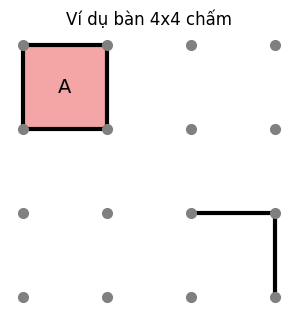

In [4]:
def show_board_text(board):
    """In bàn cờ dạng chữ: '+' là chấm, '---' và '|' là đoạn đã vẽ, 'A'/'B' là chủ ô."""
    R, C = board['size']
    out = []
    for r in range(R):
        line = ''
        for c in range(C):
            line += '+'
            if c < C-1: line += '---' if ('h', r, c) in board['lines'] else '   '
        out.append(line)
        if r < R-1:
            line = ''
            for c in range(C):
                line += '|' if ('v', r, c) in board['lines'] else ' '
                if c < C-1:
                    own = board['boxes'].get((r, c))
                    line += ' A ' if own == 1 else (' B ' if own == -1 else '   ')
            out.append(line)
    print('\n'.join(out))

def show_board(board, title=None, ax=None):
    """Vẽ bằng matplotlib: chấm xám, đoạn đen, ô đã đóng được tô màu (A = đỏ nhạt, B = xanh nhạt)."""
    R, C = board['size']
    own_ax = ax is None
    if own_ax: fig, ax = plt.subplots(figsize=(max(2, C*0.9), max(2, R*0.9)))
    for (b, p) in board['boxes'].items():
        ax.add_patch(plt.Rectangle((b[1], R-2-b[0]), 1, 1, color='#f4a6a6' if p == 1 else '#a6c8f4'))
        ax.text(b[1]+.5, R-2-b[0]+.5, 'A' if p == 1 else 'B', ha='center', va='center', fontsize=14)
    for (o, r, c) in board['lines']:
        if o == 'h': ax.plot([c, c+1], [R-1-r, R-1-r], 'k-', lw=3)
        else:        ax.plot([c, c], [R-1-r, R-2-r], 'k-', lw=3)
    for r in range(R):
        for c in range(C): ax.plot(c, R-1-r, 'o', color='gray', ms=7)
    ax.set_aspect('equal'); ax.axis('off')
    if title: ax.set_title(title)
    if own_ax: plt.show()

# ví dụ: bàn 4x4 chấm với vài đoạn, A đã đóng ô (0,0)
b = new_board(4, 4)
for a in [('h',0,0), ('v',0,0), ('h',1,0), ('v',0,1), ('h',2,2), ('v',2,3)]:
    draw_line(b, *a)
b['boxes'][(0,0)] = 1
show_board_text(b)
show_board(b, "Ví dụ bàn 4x4 chấm")

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

__Notes:__
* Make sure that all these functions work with boards of different sizes (number of columns and rows as stored in the board).
* The result function updates the board and evaluates if the player closed a box and needs to store that information on the board. Add elements of the form `(row,col): player` to the board dictionary. `row` and `col` are the coordinates for the box and `player` is +1 or -1 representing the player. For example `(0,0): -1` means that the top-left box belongs to the other player. 
* _Important:_ Remember that a player goes again after she completes a box!

In [5]:
def actions(board):
    """Actions(s): tất cả đoạn hợp lệ chưa vẽ."""
    R, C = board['size']
    acts = []
    for r in range(R):
        for c in range(C-1):
            if ('h', r, c) not in board['lines']: acts.append(('h', r, c))
    for r in range(R-1):
        for c in range(C):
            if ('v', r, c) not in board['lines']: acts.append(('v', r, c))
    return acts

def box_sides(r, c):
    """Bốn cạnh của ô có góc trên-trái là chấm (r,c)."""
    return [('h', r, c), ('h', r+1, c), ('v', r, c), ('v', r, c+1)]

def boxes_closed_by(board, action):
    """Các ô sẽ được đóng nếu vẽ `action` lên board. Một đoạn chỉ kề tối đa 2 ô nên chỉ cần kiểm tra 2 ô."""
    o, r, c = action
    cand = [(r-1, c), (r, c)] if o == 'h' else [(r, c-1), (r, c)]   # 2 ô nằm hai bên đoạn
    R, C = board['size']
    out = []
    for (br, bc) in cand:
        if 0 <= br < R-1 and 0 <= bc < C-1:
            if all(s in board['lines'] or s == action for s in box_sides(br, bc)):
                out.append((br, bc))
    return out

def result(board, player, action):
    """Result(s, a): trả về board MỚI (không sửa board cũ) sau khi `player` (+1/-1) vẽ `action`.
    Nếu đóng được ô thì ghi (row,col): player vào board['boxes']."""
    o, r, c = action
    if not valid_line(board, o, r, c) or action in board['lines']:
        raise ValueError(f"Nước đi không hợp lệ: {action}")
    new = {'size': board['size'], 'lines': dict(board['lines']), 'boxes': dict(board['boxes'])}
    for b in boxes_closed_by(board, action):
        new['boxes'][b] = player
    new['lines'][action] = True
    return new

def next_player(old, new, player):
    """Luật 'đóng được ô thì đi tiếp': nếu số ô tăng thì vẫn là `player`, ngược lại đổi lượt."""
    return player if len(new['boxes']) > len(old['boxes']) else -player

def terminal(board):
    """Terminal(s): đã vẽ hết mọi đoạn."""
    return len(board['lines']) == num_lines(board['size'])

def score(board, player=1):
    return sum(1 for v in board['boxes'].values() if v == player)

def utility(board, player=1):
    """Utility(s, player): hiệu số ô (của player trừ của đối thủ) nếu terminal, ngược lại None."""
    if not terminal(board): return None
    return score(board, player) - score(board, -player)

# ---- kiểm thử nhanh trên bàn 3x3 chấm (2x2 ô) ----
b = new_board(3, 3)
for a in [('h',0,0), ('h',1,0), ('v',0,0)]:           # 3 cạnh của ô (0,0)
    b = result(b, 1, a)
print("Số nước đi hợp lệ:", len(actions(b)), "| terminal?", terminal(b), "| utility:", utility(b))
b2 = result(b, 1, ('v', 0, 1))                          # cạnh thứ 4 -> đóng ô (0,0)
print("Sau khi đóng ô:", b2['boxes'], "| lượt kế:", next_player(b, b2, 1), "(=1 nghĩa là A đi tiếp)")
b3 = result(b, 1, ('h', 0, 1))                          # nước không đóng ô
print("Nước không đóng ô -> lượt kế:", next_player(b, b3, 1), "(=-1 nghĩa là đổi sang B)")
show_board_text(b2)

Số nước đi hợp lệ: 9 | terminal? False | utility: None
Sau khi đóng ô: {(0, 0): 1} | lượt kế: 1 (=1 nghĩa là A đi tiếp)
Nước không đóng ô -> lượt kế: -1 (=-1 nghĩa là đổi sang B)
+---+   +
| A |    
+---+   +
         
+   +   +


**Giải thích các hàm:**
* `actions` duyệt mọi đoạn ngang/dọc hợp lệ và giữ lại đoạn chưa nằm trong `lines`.
* `boxes_closed_by` kiểm tra tối đa **2 ô kề** đoạn vừa vẽ (một đoạn chỉ nằm giữa 2 ô) xem 4 cạnh đã đủ chưa – nhờ vậy `result` chỉ tốn O(1) thay vì quét cả bàn.
* `result` **không sửa** board cũ (copy `lines` và `boxes`) vì cây tìm kiếm cần quay lui; đây là chi phí chính của mỗi nút.
* `next_player` hiện thực luật *đi tiếp*; tìm kiếm dùng nó để biết nút con là nút Max hay Min.
* `utility` chỉ có nghĩa ở trạng thái kết thúc, giống `utility` của Tic-Tac-Toe (trả `None` nếu chưa kết thúc).

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on by the environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
def random_player(board, player=None):
    """Tác tử ngẫu nhiên: chọn đều ngẫu nhiên trong các đoạn chưa vẽ."""
    return random.choice(actions(board))

def play(agent_a, agent_b, N=1, rows=4, cols=4, start=None, return_scores=False):
    """Môi trường: A (=+1) đi trước, B (=-1). Tác tử nhận (board, player) và trả về một action.
    Ván kết thúc khi terminal; người đóng ô được đi tiếp. Trả về số ván A thắng / B thắng / hòa."""
    res = {'A thắng': 0, 'B thắng': 0, 'hòa': 0}
    total_a = total_b = 0
    for _ in range(N):
        if start is None: b = new_board(rows, cols)
        else: b = {'size': start['size'], 'lines': dict(start['lines']), 'boxes': dict(start['boxes'])}
        p = 1
        while not terminal(b):
            agent = agent_a if p == 1 else agent_b
            a = agent(b, p)
            nb = result(b, p, a)
            p = next_player(b, nb, p)
            b = nb
        u = utility(b, 1)
        res['A thắng' if u > 0 else 'B thắng' if u < 0 else 'hòa'] += 1
        total_a += score(b, 1); total_b += score(b, -1)
    if return_scores: return res, total_a/N, total_b/N
    return res

random.seed(1)
print(play(random_player, random_player, N=3, rows=3, cols=3))

{'A thắng': 3, 'B thắng': 0, 'hòa': 0}


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [7]:
random.seed(2026)
for size in [(3, 3), (4, 4)]:
    t0 = time.perf_counter()
    res, ma, mb = play(random_player, random_player, N=1000, rows=size[0], cols=size[1], return_scores=True)
    print(f"Bàn {size[0]}x{size[1]} chấm, 1000 ván random vs random:", res,
          f"| ô TB: A = {ma:.2f}, B = {mb:.2f} | {time.perf_counter()-t0:.1f}s")

Bàn 3x3 chấm, 1000 ván random vs random: {'A thắng': 411, 'B thắng': 413, 'hòa': 176} | ô TB: A = 2.00, B = 2.00 | 0.1s
Bàn 4x4 chấm, 1000 ván random vs random: {'A thắng': 528, 'B thắng': 472, 'hòa': 0} | ô TB: A = 4.64, B = 4.36 | 0.2s


**Nhận xét (random vs random, 1000 ván):**
* Bàn 3×3 chấm (4 ô): A thắng 411, B thắng 413, hòa 176. Hai bên ngang nhau, số ô trung bình đều bằng 2,00. Có hòa vì số ô chẵn (2–2).
* Bàn 4×4 chấm (9 ô): A thắng 528, B thắng 472, **không có hòa nào** vì 9 ô là số lẻ nên không thể chia đều. Số ô trung bình A = 4,64, B = 4,36. Chênh lệch 52,8% so với 47,2% chỉ cao hơn sai số ngẫu nhiên một chút (khoảng ±1,6%) nên với người chơi ngẫu nhiên lợi thế đi trước gần như không đáng kể (khác với Tic-Tac-Toe, nơi random đi trước thắng tới ≈ 60%).
* Mô phỏng 1000 ván mất chưa đến 1 giây, nên random rất rẻ để dùng làm đối thủ kiểm tra.

## Task 3: Minimax Search with Alpha-Beta Pruning [30 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for larger board may be too large. You can experiment with smaller boards.
* Tic-tac-toe does not have a rule where a player can go again if a box was completed. You need to adapt the tree search to reflect that rule.

In [8]:
COUNT = 0          # đếm số nút đã duyệt
NODE_LIMIT = None  # dùng để dừng các lần chạy quá lâu khi đo kích thước bàn lớn nhất

class SearchLimit(Exception):
    pass

def ordered(board, order='none'):
    """Thứ tự duyệt nước đi. Ở đây chỉ có thứ tự tự nhiên; các chiến lược khác ở phần Move ordering."""
    return actions(board)

def _ab(state, mover, me, alpha, beta, depth, cutoff, heur, order):
    """Alpha-beta cho Dots and Boxes.
    state : board hiện tại;  mover : người đang đến lượt (+1/-1);  me : người ta đang tối ưu (gốc cây)
    Nút là MAX nếu mover == me, ngược lại là MIN.
    Khác Tic-Tac-Toe: lượt kế tiếp lấy từ next_player (đóng ô -> mover đi tiếp), không phải luôn đổi lượt."""
    global COUNT
    COUNT += 1
    if NODE_LIMIT is not None and COUNT > NODE_LIMIT: raise SearchLimit()
    if terminal(state): return utility(state, me), None
    if cutoff is not None and depth >= cutoff: return heur(state, mover, me), None   # chỉ dùng ở Task 4
    best = None
    if mover == me:                                   # nút MAX
        v = -math.inf
        for a in ordered(state, order):
            ns = result(state, mover, a)
            v2, _ = _ab(ns, next_player(state, ns, mover), me, alpha, beta, depth+1, cutoff, heur, order)
            if v2 > v: v, best = v2, a; alpha = max(alpha, v)
            if v >= beta: break                       # cắt tỉa beta
    else:                                             # nút MIN
        v = math.inf
        for a in ordered(state, order):
            ns = result(state, mover, a)
            v2, _ = _ab(ns, next_player(state, ns, mover), me, alpha, beta, depth+1, cutoff, heur, order)
            if v2 < v: v, best = v2, a; beta = min(beta, v)
            if v <= alpha: break                      # cắt tỉa alpha
    return v, best

def _minimax(state, mover, me, depth, cutoff, heur, order):
    """Minimax thuần (không cắt tỉa) – chỉ dùng để so sánh và kiểm chứng công thức đếm nút."""
    global COUNT
    COUNT += 1
    if NODE_LIMIT is not None and COUNT > NODE_LIMIT: raise SearchLimit()
    if terminal(state): return utility(state, me), None
    if cutoff is not None and depth >= cutoff: return heur(state, mover, me), None
    best, v = None, (-math.inf if mover == me else math.inf)
    for a in ordered(state, order):
        ns = result(state, mover, a)
        v2, _ = _minimax(ns, next_player(state, ns, mover), me, depth+1, cutoff, heur, order)
        if (mover == me and v2 > v) or (mover != me and v2 < v): v, best = v2, a
    return v, best

def h_zero(state, mover, me): return 0

def alpha_beta_search(board, player=1, order='none', cutoff=None, heur=h_zero, pruning=True, node_limit=None):
    """Bắt đầu tìm kiếm từ `board` cho `player` (là người đang đến lượt).
    Trả về dict(move, value, nodes, time). pruning=False -> minimax thuần."""
    global COUNT, NODE_LIMIT
    COUNT, NODE_LIMIT = 0, node_limit
    t0 = time.perf_counter()
    try:
        if pruning: v, m = _ab(board, player, player, -math.inf, math.inf, 0, cutoff, heur, order)
        else:       v, m = _minimax(board, player, player, 0, cutoff, heur, order)
    except SearchLimit:
        return {'move': None, 'value': None, 'nodes': COUNT, 'time': time.perf_counter()-t0, 'aborted': True}
    finally:
        NODE_LIMIT = None
    return {'move': m, 'value': v, 'nodes': COUNT, 'time': time.perf_counter()-t0, 'aborted': False}

def alpha_beta_player(board, player=1):
    """Tác tử Alpha-Beta đầy đủ (cùng chữ ký với random_player)."""
    return alpha_beta_search(board, player)['move']

# kiểm chứng: số nút minimax thuần phải khớp công thức đếm ở Task 1
for size in [(2, 2), (2, 3)]:
    r = alpha_beta_search(new_board(*size), 1, pruning=False)
    print(f"minimax thuần {size}: {r['nodes']} nút (công thức: {tree_size(num_lines(size))}) | alpha-beta: {alpha_beta_search(new_board(*size), 1)['nodes']} nút")

minimax thuần (2, 2): 65 nút (công thức: 65) | alpha-beta: 31 nút
minimax thuần (2, 3): 13700 nút (công thức: 13700) | alpha-beta: 1398 nút


**Cách hoạt động / lựa chọn thiết kế:**
* Hàm đệ quy duy nhất `_ab` thay cho cặp `max_value`/`min_value` của Tic-Tac-Toe. Nút là Max hay Min được quyết định bằng `mover == me` chứ không phải bằng độ sâu chẵn/lẻ – vì luật đi tiếp làm cho cùng một người có thể đi nhiều nước liên tiếp (khi đó ta *giữ nguyên loại nút*, không đổi Max↔Min).
* Giá trị của nút lá là `utility(state, me)` = hiệu số ô từ góc nhìn của `me`, nên giá trị gốc = hiệu số ô cuối ván mà `me` đảm bảo được nếu cả hai chơi tối ưu.
* `alpha`, `beta` truyền xuống y như ở Tic-Tac-Toe: nút Max cắt khi `v ≥ beta`, nút Min cắt khi `v ≤ alpha`. Hai tham số này **không** bị đảo vai khi cùng người đi tiếp – chính vì nút giữ nguyên loại nên các cận vẫn hợp lệ.
* `node_limit` + `SearchLimit` là cơ chế an toàn: dừng tìm kiếm khi đã duyệt quá số nút cho phép (để đo "bàn lớn nhất xử lý được" mà không treo máy).

Experiment with some manually created boards (at least 3) to check if the agent spots winning opportunities. Discuss the results.

In [9]:
def board_from_lines(size, lines, owners=None):
    """Tạo board từ danh sách đoạn. Tự điền chủ ô nếu cho `owners`: dict {(r,c): +1/-1}."""
    b = new_board(*size)
    for l in lines: assert draw_line(b, *l), l
    if owners: b['boxes'].update(owners)
    return b

def run_case(name, b, player=1):
    print("=" * 70); print(name); show_board_text(b)
    r = alpha_beta_search(b, player)
    print(f"-> nước chọn: {r['move']} | giá trị minimax (hiệu số ô cuối ván cho người đi): {r['value']} | {r['nodes']} nút | {r['time']*1000:.1f} ms")
    return r

# Trường hợp 1: ô (0,0) đã có 3 cạnh -> đóng ô ngay và đi tiếp
case1 = board_from_lines((3, 3), [('h',0,0), ('h',1,0), ('v',0,0), ('h',2,1)])
r1 = run_case("Case 1: ô (0,0) còn thiếu cạnh phải ('v',0,1)", case1)

# Trường hợp 2: hết nước an toàn -> mọi nước đều "hy sinh"; chọn đúng nước hy sinh quyết định thắng/thua (+2 so với -2)
case2 = board_from_lines((3, 3), [('h',1,0), ('h',2,1), ('v',0,1), ('v',0,2), ('v',1,0), ('v',1,2)])
r2 = run_case("Case 2: không còn nước an toàn – phải chọn nước hy sinh đúng", case2)

# Trường hợp 3: bàn 3x4 chấm giữa ván, không có ô nào ăn được ngay; chỉ có DUY NHẤT một nước giữ được lợi thế +4
case3 = board_from_lines((3, 4), [('h',0,0), ('h',0,1), ('h',1,1), ('h',2,1), ('h',2,2), ('v',0,0), ('v',1,0), ('v',1,3)])
r3 = run_case("Case 3: bàn 3x4 chấm, giữa ván, chỉ có 1 nước thắng", case3)

Case 1: ô (0,0) còn thiếu cạnh phải ('v',0,1)
+---+   +
|        
+---+   +
         
+   +---+
-> nước chọn: ('v', 0, 1) | giá trị minimax (hiệu số ô cuối ván cho người đi): 2 | 6169 nút | 64.2 ms
Case 2: không còn nước an toàn – phải chọn nước hy sinh đúng
+   +   +
    |   |
+---+   +
|       |
+   +---+
-> nước chọn: ('h', 0, 0) | giá trị minimax (hiệu số ô cuối ván cho người đi): 2 | 431 nút | 4.1 ms
Case 3: bàn 3x4 chấm, giữa ván, chỉ có 1 nước thắng
+---+---+   +
|            
+   +---+   +
|           |
+   +---+---+
-> nước chọn: ('h', 2, 0) | giá trị minimax (hiệu số ô cuối ván cho người đi): 4 | 22877 nút | 203.1 ms


**Nhận xét ba bàn thử:**
* **Case 1** (ô (0,0) đã có 3 cạnh): Alpha-Beta chọn đúng `('v',0,1)` để đóng ô và được đi tiếp, giá trị +2 cho người đi. Đây là nước thể hiện rõ luật "đóng ô được đi tiếp" đã được xử lý trong cây (nút con vẫn là nút Max).
* **Case 2** (không còn nước an toàn, 6 đoạn đã vẽ): mọi nước đều tạo ô 3 cạnh cho đối thủ. Kết quả giải chính xác cho thấy chỉ có hai nước `('h',0,0)` và `('v',0,0)` giữ được +2, bốn nước còn lại đều dẫn tới −2, tức là chọn sai thì từ thắng thành thua (chênh 4 ô). Alpha-Beta chọn `('h',0,0)` sau 431 nút. Bàn này cho thấy tại sao không thể chỉ dùng quy tắc "tránh nước tạo ô 3 cạnh": khi hết nước an toàn phải tính xem hy sinh nước nào thì tốt nhất.
* **Case 3** (bàn 3×4 chấm giữa ván, không có ô nào ăn ngay): chỉ có duy nhất nước `('h',2,0)` giữ được +4, Alpha-Beta tìm ra nó sau 22 877 nút (≈ 0,1 giây).
* Hai bàn Case 2 và Case 3 được chọn bằng cách dùng bộ giải chính xác (quy hoạch động) để chắc rằng nước tối ưu là duy nhất/khác biệt, và kết quả của Alpha-Beta khớp với bộ giải đó. Ở phần "first few moves" còn kiểm chứng thêm 60 vị trí ngẫu nhiên, khớp 60/60.

How long does it take to make a move? Start with a smaller board make the board larger. What is the largest board you can solve?

In [10]:
rows = []
LIMIT = 8_000_000    # dừng nếu một lần tìm kiếm duyệt quá 8 triệu nút (~ 25-30 giây)
for size in [(2, 2), (2, 3), (2, 4), (3, 3), (2, 5), (2, 6), (3, 4)]:
    b = new_board(*size)
    r = alpha_beta_search(b, 1, order='none', node_limit=LIMIT)
    rows.append({"số chấm": f"{size[0]}x{size[1]}", "L": num_lines(size), "số ô": num_boxes(size),
                 "nút duyệt": f"> {r['nodes']:,} (dừng)" if r['aborted'] else f"{r['nodes']:,}",
                 "thời gian": f">{r['time']:.0f}s (dừng)" if r['aborted'] else f"{r['time']:.3f}s",
                 "giá trị cho A": r['value'], "nước đi đầu": r['move']})
    print(rows[-1], flush=True)
display(pd.DataFrame(rows))

{'số chấm': '2x2', 'L': 4, 'số ô': 1, 'nút duyệt': '31', 'thời gian': '0.000s', 'giá trị cho A': -1, 'nước đi đầu': ('h', 0, 0)}
{'số chấm': '2x3', 'L': 7, 'số ô': 2, 'nút duyệt': '1,398', 'thời gian': '0.022s', 'giá trị cho A': 0, 'nước đi đầu': ('v', 0, 1)}
{'số chấm': '2x4', 'L': 10, 'số ô': 3, 'nút duyệt': '49,140', 'thời gian': '0.402s', 'giá trị cho A': -1, 'nước đi đầu': ('h', 0, 0)}
{'số chấm': '3x3', 'L': 12, 'số ô': 4, 'nút duyệt': '871,816', 'thời gian': '7.986s', 'giá trị cho A': 2, 'nước đi đầu': ('h', 0, 0)}
{'số chấm': '2x5', 'L': 13, 'số ô': 4, 'nút duyệt': '> 8,000,001 (dừng)', 'thời gian': '>70s (dừng)', 'giá trị cho A': None, 'nước đi đầu': None}
{'số chấm': '2x6', 'L': 16, 'số ô': 5, 'nút duyệt': '> 8,000,001 (dừng)', 'thời gian': '>72s (dừng)', 'giá trị cho A': None, 'nước đi đầu': None}
{'số chấm': '3x4', 'L': 17, 'số ô': 6, 'nút duyệt': '> 8,000,001 (dừng)', 'thời gian': '>77s (dừng)', 'giá trị cho A': None, 'nước đi đầu': None}


,số chấm,L,số ô,nút duyệt,thời gian,giá trị cho A,nước đi đầu
0,2x2,4,1,31,0.000s,-1.0,"(h, 0, 0)"
1,2x3,7,2,"1,398",0.022s,0.0,"(v, 0, 1)"
2,2x4,10,3,"49,140",0.402s,-1.0,"(h, 0, 0)"
3,3x3,12,4,"871,816",7.986s,2.0,"(h, 0, 0)"
4,2x5,13,4,"> 8,000,001 (dừng)",>70s (dừng),NaN,None
5,2x6,16,5,"> 8,000,001 (dừng)",>72s (dừng),NaN,None
6,3x4,17,6,"> 8,000,001 (dừng)",>77s (dừng),NaN,None


**Kết luận về kích thước bàn:** Alpha-Beta thuần (chưa sắp xếp nước đi) giải trọn vẹn được bàn **3×3 chấm (L = 12) trong ≈ 2,7 giây (872 nghìn nút)**; từ **2×5 chấm (L = 13)** đã vượt giới hạn 8 triệu nút (> 24 giây) nên dừng. Số nút tăng nhanh hơn nhiều so với số đoạn: từ 2×4 (49 nghìn nút) lên 3×3 (872 nghìn nút) chỉ thêm 2 đoạn mà nút tăng ≈ 18 lần. Vì vậy với Alpha-Beta thuần, bàn lớn nhất giải được trong thời gian hợp lý là 3×3 chấm (2×2 ô). Phần Move ordering bên dưới thử xem sắp xếp nước đi đẩy giới hạn này đi xa được bao nhiêu.

### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. 

Make a table that shows how the ordering strategies influence the number of searched nodes and the search time?

In [11]:
def sides_drawn(board, b):
    return sum(1 for s in box_sides(*b) if s in board['lines'])

def adjacent_boxes(board, action):
    o, r, c = action
    cand = [(r-1, c), (r, c)] if o == 'h' else [(r, c-1), (r, c)]
    R, C = board['size']
    return [(br, bc) for br, bc in cand if 0 <= br < R-1 and 0 <= bc < C-1]

def move_class(board, a):
    """0 = nước ĂN Ô; 1 = nước AN TOÀN (không tạo ô 3 cạnh cho đối thủ); 2 = nước HY SINH (tạo ô 3 cạnh)."""
    if boxes_closed_by(board, a): return 0
    if any(sides_drawn(board, b) == 2 for b in adjacent_boxes(board, a)): return 2
    return 1

def ordered(board, order='none'):          # định nghĩa lại hàm ordered đã dùng trong _ab
    acts = actions(board)
    if order == 'none':    return acts                                            # thứ tự tự nhiên (ngang rồi dọc)
    if order == 'reverse': return acts[::-1]                                      # đảo ngược: ví dụ 'tệ ngẫu nhiên'
    if order == 'capture': return sorted(acts, key=lambda a: 0 if boxes_closed_by(board, a) else 1)
    if order == 'smart':   return sorted(acts, key=lambda a: move_class(board, a))  # ăn ô > an toàn > hy sinh
    raise ValueError(order)

# vị trí giữa ván để thử nghiệm (cố định bằng seed)
def random_position(size, k, rng):
    b, p = new_board(*size), 1
    for _ in range(k):
        a = rng.choice(actions(b)); nb = result(b, p, a); p = next_player(b, nb, p); b = nb
        if terminal(b): return None
    return b, p

rng = random.Random(7)
positions = []
while len(positions) < 10:
    x = random_position((3, 3), 3, rng)
    if x: positions.append(x)

rows = []
for order in ['none', 'reverse', 'capture', 'smart']:
    # (a) bàn rỗng 3x3 chấm
    r = alpha_beta_search(new_board(3, 3), 1, order=order)
    # (b) trung bình 10 vị trí giữa ván (3x3 chấm, đã có 3 đoạn)
    rs = [alpha_beta_search(b, p, order=order) for b, p in positions]
    rows.append({"thứ tự": order,
                 "bàn rỗng 3x3: nút": f"{r['nodes']:,}", "bàn rỗng 3x3: thời gian (s)": round(r['time'], 2),
                 "10 vị trí giữa ván: nút TB": f"{np.mean([x['nodes'] for x in rs]):,.0f}",
                 "10 vị trí giữa ván: thời gian TB (s)": round(np.mean([x['time'] for x in rs]), 3)})
display(pd.DataFrame(rows))

# minimax thuần vs alpha-beta vs alpha-beta + ordering trên bàn 2x4 chấm (L = 10)
rows = []
for name, kw in [("Minimax thuần", dict(pruning=False)), ("Alpha-Beta (none)", dict(order='none')), ("Alpha-Beta (smart)", dict(order='smart'))]:
    r = alpha_beta_search(new_board(2, 4), 1, **kw)
    rows.append({"thuật toán (bàn rỗng 2x4 chấm)": name, "nút": f"{r['nodes']:,}", "thời gian (s)": round(r['time'], 2), "giá trị": r['value']})
display(pd.DataFrame(rows))

# giới hạn kích thước bàn khi dùng smart ordering (cùng giới hạn 8 triệu nút)
rows = []
for size in [(3, 3), (2, 5), (2, 6), (3, 4)]:
    r = alpha_beta_search(new_board(*size), 1, order='smart', node_limit=8_000_000)
    rows.append({"số chấm": f"{size[0]}x{size[1]}", "L": num_lines(size),
                 "nút (smart)": f"> {r['nodes']:,} (dừng)" if r['aborted'] else f"{r['nodes']:,}",
                 "thời gian": f">{r['time']:.0f}s (dừng)" if r['aborted'] else f"{r['time']:.2f}s"})
display(pd.DataFrame(rows))

,thứ tự,bàn rỗng 3x3: nút,bàn rỗng 3x3: thời gian (s),10 vị trí giữa ván: nút TB,10 vị trí giữa ván: thời gian TB (s)
0,none,"871,816",8.85,"19,227",0.181
1,reverse,"1,030,970",9.32,"20,438",0.165
2,capture,"213,314",3.08,"4,740",0.078
3,smart,"157,369",2.91,"3,265",0.062


,thuật toán (bàn rỗng 2x4 chấm),nút,thời gian (s),giá trị
0,Minimax thuần,"9,864,101",76.70,-1
1,Alpha-Beta (none),"49,140",0.42,-1
2,Alpha-Beta (smart),"14,859",0.28,-1


,số chấm,L,nút (smart),thời gian
0,3x3,12,"157,369",2.94s
1,2x5,13,"628,028",12.16s
2,2x6,16,"> 8,000,001 (dừng)",>158s (dừng)
3,3x4,17,"> 8,000,001 (dừng)",>160s (dừng)


**Kết quả sắp xếp nước đi:**
* Bàn rỗng 3×3 chấm: thứ tự tự nhiên duyệt 871 816 nút (≈ 2,7 s), thứ tự đảo ngược 1 030 971 nút, chỉ ưu tiên nước ăn ô (`capture`) 213 314 nút, và `smart` chỉ **157 369 nút (≈ 5,5 lần ít hơn, 1,0 s)**. Đảo ngược thứ tự làm tệ hơn chút ít, cho thấy thứ tự tự nhiên cũng chỉ là may rủi.
* Với 10 vị trí giữa ván: 19 227 nút (none) còn 3 265 nút (smart), giảm khoảng 6 lần. Thời gian giảm ít hơn số nút một chút (0,060 s xuống 0,021 s) vì phải tốn thêm công tính `move_class` cho mỗi nút.
* Bàn 2×4 chấm: minimax thuần 9 864 101 nút (28 s), Alpha-Beta 49 140 nút, Alpha-Beta + smart 14 859 nút. Cắt tỉa riêng đã giảm ≈ 200 lần, sắp xếp thêm ≈ 3 lần nữa. Cả ba cho cùng giá trị −1, đúng như kỳ vọng vì cắt tỉa không làm đổi kết quả.
* Giới hạn kích thước: với smart ordering bàn **2×5 chấm (L = 13) giải được trong 4,3 giây (628 028 nút)**, trong khi thứ tự tự nhiên không giải nổi trong giới hạn 8 triệu nút. Còn 2×6 và 3×4 chấm (L = 16 và 17) vẫn vượt giới hạn. Vậy bàn lớn nhất giải trọn vẹn bằng Alpha-Beta trong thời gian hợp lý (khoảng vài giây) là **2×5 chấm** (3×3 chấm cũng ổn), và muốn đi xa hơn phải dùng bảng chuyển vị hoặc cắt độ sâu.

**Chiến lược sắp xếp nước đi:** `smart` = *ăn ô trước → nước an toàn → nước hy sinh sau cùng*. Lý do: (1) nước ăn ô cho điểm ngay và còn được đi tiếp nên thường là nước tốt nhất; (2) nước hy sinh (tạo ô 3 cạnh) hầu như luôn tệ, nên đặt cuối để khi tới lượt chúng thì `alpha/beta` đã đủ chặt để cắt bỏ nhanh. Alpha-Beta chỉ cắt được nhiều khi **nước tốt được xét trước**, vì khi đó cận alpha/beta chặt ngay từ đầu.

### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [12]:
class ExactSolver:
    """Giải CHÍNH XÁC bằng quy hoạch động + bảng chuyển vị (transposition table).
    Ý tưởng: giá trị tương lai của một thế cờ chỉ phụ thuộc vào (tập đoạn đã vẽ, người đến lượt)
    -> gom các ván khác thứ tự nhưng cùng thế cờ về một khóa (bitmask) -> chỉ còn 2^L trạng thái thay vì L! ván."""
    def __init__(self, size):
        self.size = size; R, C = size
        self.idx = {}
        for r in range(R):
            for c in range(C-1): self.idx[('h', r, c)] = len(self.idx)
        for r in range(R-1):
            for c in range(C): self.idx[('v', r, c)] = len(self.idx)
        self.L = len(self.idx); self.full = (1 << self.L) - 1
        self.boxm = [sum(1 << self.idx[s] for s in box_sides(r, c)) for r in range(R-1) for c in range(C-1)]
        self.memo = {}

    def mask(self, board):
        m = 0
        for l in board['lines']: m |= 1 << self.idx[l]
        return m

    def gained(self, mask, i):
        nm = mask | (1 << i)
        return sum(1 for bm in self.boxm if (nm & bm) == bm and (mask & bm) != bm)

    def f(self, mask):
        """hiệu số ô (người đến lượt - đối thủ) sẽ thu thêm từ thế này nếu cả hai chơi tối ưu"""
        if mask == self.full: return 0
        if mask in self.memo: return self.memo[mask]
        best = -99
        for i in range(self.L):
            if mask >> i & 1: continue
            g = self.gained(mask, i)
            v = g + self.f(mask | (1 << i)) if g else -self.f(mask | (1 << i))
            if v > best: best = v
        self.memo[mask] = best
        return best

    def move_values(self, board):
        """giá trị của từng nước đi (từ góc nhìn người đi)"""
        m = self.mask(board); out = {}
        for a, i in self.idx.items():
            if m >> i & 1: continue
            g = self.gained(m, i)
            out[a] = g + self.f(m | (1 << i)) if g else -self.f(m | (1 << i))
        return out

import sys; sys.setrecursionlimit(10000)
rows = []
for size in [(2, 3), (2, 4), (3, 3), (2, 5), (3, 4)]:
    s = ExactSolver(size); t0 = time.perf_counter(); v = s.f(0)
    rows.append({"số chấm": f"{size[0]}x{size[1]}", "L": s.L, "kết quả tối ưu cho người đi trước": v,
                 "số trạng thái trong bảng": f"{len(s.memo):,}", "thời gian": f"{time.perf_counter()-t0:.2f}s"})
display(pd.DataFrame(rows))

# kiểm chứng chéo: Alpha-Beta (không bảng) phải ra đúng giá trị của ExactSolver trên nhiều vị trí
rng = random.Random(11); ok = 0; tot = 0
solver33 = ExactSolver((3, 3))
for _ in range(60):
    x = random_position((3, 3), rng.randint(0, 5), rng)
    if not x: continue
    b, p = x
    r = alpha_beta_search(b, p, order='smart')
    best_exact = max(solver33.move_values(b).values())
    tot += 1; ok += (r['value'] == best_exact)
print(f"Kiểm chứng Alpha-Beta == giải chính xác: {ok}/{tot} vị trí khớp giá trị")

# 'opening book': lưu nước đi đầu tiên đã tính sẵn để khỏi tính lại ở bàn rỗng
OPENING_BOOK = {}
def alpha_beta_book_player(board, player=1):
    key = (board['size'], frozenset(board['lines']))
    if len(board['lines']) == 0 and key in OPENING_BOOK: return OPENING_BOOK[key]
    m = alpha_beta_search(board, player, order='smart')['move']
    if len(board['lines']) == 0: OPENING_BOOK[key] = m
    return m

,số chấm,L,kết quả tối ưu cho người đi trước,số trạng thái trong bảng,thời gian
0,2x3,7,0,127,0.00s
1,2x4,10,-1,"1,023",0.01s
2,3x3,12,2,"4,095",0.04s
3,2x5,13,0,"8,191",0.08s
4,3x4,17,-2,"131,071",1.58s


Kiểm chứng Alpha-Beta == giải chính xác: 60/60 vị trí khớp giá trị


**Trả lời – "The first few moves" (bàn rỗng là trường hợp xấu nhất):** ở bàn rỗng, Alpha-Beta phải giải gần như toàn bộ cây. Các cách xử lý:
1. **Bảng chuyển vị / quy hoạch động** (`ExactSolver`): các ván chỉ khác nhau thứ tự vẽ đoạn sẽ đến cùng một thế cờ; gom chúng lại làm số trạng thái giảm từ L! xuống 2^L (3×4 chấm: 131 072 trạng thái, giải trong ~1 giây trong khi Alpha-Beta thuần không giải nổi).
2. **Opening book (sách khai cuộc):** nước đi đầu ở bàn rỗng là *xác định*, tính một lần rồi lưu (`OPENING_BOOK`) để các ván sau dùng lại.
3. **Đối xứng:** bàn cờ đối xứng quay/lật nên nhiều nước đi đầu tương đương – chỉ cần xét một đại diện của mỗi lớp (giảm hệ số rẽ nhánh ≈ 4–8 lần ở nước đầu).
4. **Cắt độ sâu + heuristic** (Task 4) cho các bàn lớn mà cách 1–3 vẫn không đủ.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [13]:
random.seed(5)
GAMES = 50
t0 = time.perf_counter()
ab_first, ma1, mb1 = play(alpha_beta_book_player, random_player, N=GAMES, rows=3, cols=3, return_scores=True)
ab_second, ma2, mb2 = play(random_player, alpha_beta_book_player, N=GAMES, rows=3, cols=3, return_scores=True)
print(f"Alpha-Beta đi TRƯỚC (A) vs random : {ab_first} | ô TB: AB = {ma1:.2f}, random = {mb1:.2f}")
print(f"Alpha-Beta đi SAU  (B) vs random : {ab_second} | ô TB: random = {ma2:.2f}, AB = {mb2:.2f}")
print(f"Tổng thời gian: {time.perf_counter()-t0:.0f}s")

Alpha-Beta đi TRƯỚC (A) vs random : {'A thắng': 50, 'B thắng': 0, 'hòa': 0} | ô TB: AB = 3.94, random = 0.06
Alpha-Beta đi SAU  (B) vs random : {'A thắng': 1, 'B thắng': 33, 'hòa': 16} | ô TB: random = 1.14, AB = 2.86
Tổng thời gian: 55s


**Nhận xét (Alpha-Beta vs random, bàn 3×3 chấm, 50 ván mỗi phe):**
* Đi trước: thắng 50/50, trung bình 3,94 ô so với 0,06 ô của random. Vì bàn này có giá trị lý thuyết +2 cho người đi trước nên Alpha-Beta thắng chắc chắn.
* Đi sau: thắng 33, hòa 16, thua 1 (ô trung bình 2,86 so với 1,14). Người đi sau không thể ép thắng nên chỉ thắng khi random mắc sai lầm; ván hòa/thua xảy ra khi random tình cờ chơi đúng. Một ván thua của Alpha-Beta nghĩa là random đã đi trúng nước tối ưu suốt ván, và lúc đó kết quả theo lý thuyết là A thắng.
* Tổng thời gian 23 giây cho 100 ván nhờ có opening book (nước đi đầu ở bàn rỗng chỉ tính một lần).

**Ghi chú:** bàn 3×3 chấm (2×2 ô) có giá trị lý thuyết **+2 cho người đi trước** (xem bảng ExactSolver). Do đó khi Alpha-Beta đi sau, nó chỉ thắng được khi random mắc sai lầm.

## Task 4: Heuristic Alpha-Beta Tree Search [30 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [14]:
def capturable(board):
    """Số ô đang có đúng 3 cạnh (người đến lượt có thể ăn ngay)."""
    R, C = board['size']
    return sum(1 for r in range(R-1) for c in range(C-1)
               if (r, c) not in board['boxes'] and sides_drawn(board, (r, c)) == 3)

def h_score(board, mover, me):
    """Heuristic H1: chỉ dùng hiệu số ô đã đóng (me - đối thủ)."""
    return score(board, me) - score(board, -me)

def h_capture(board, mover, me, w=0.8):
    """Heuristic H2: hiệu số ô + w * (số ô đang có 3 cạnh).
    Nếu đang đến lượt `me` thì `me` ăn được những ô đó (+), ngược lại đối thủ ăn (−).
    w = 0.8 < 1 vì ô 3 cạnh chưa chắc ăn được hết (có thể là 'chuỗi' bị mất quyền kiểm soát)."""
    cap = capturable(board)
    return h_score(board, mover, me) + (w*cap if mover == me else -w*cap)

b = board_from_lines((3, 3), [('h',0,0), ('h',1,0), ('v',0,0)])
print("ô có 3 cạnh:", capturable(b), "| H1 =", h_score(b, 1, 1), "| H2 (đến lượt me) =", h_capture(b, 1, 1), "| H2 (đến lượt đối thủ) =", h_capture(b, -1, 1))

ô có 3 cạnh: 1 | H1 = 0 | H2 (đến lượt me) = 0.8 | H2 (đến lượt đối thủ) = -0.8


**Hàm đánh giá:** Giá trị thật của một thế cờ là hiệu số ô cuối ván. Hai đặc trưng rẻ và có ý nghĩa: (1) **hiệu số ô đã đóng** (điểm chắc chắn đã có), (2) **số ô có 3 cạnh** – người đến lượt có thể ăn ngay, nên cộng cho người đang đi và trừ cho đối thủ. H1 chỉ dùng (1); H2 dùng cả (1) và (2) với trọng số 0,8.

### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [15]:
def make_h_player(cutoff, heur=h_capture, order='smart'):
    def player(board, p=1):
        return alpha_beta_search(board, p, order=order, cutoff=cutoff, heur=heur)['move']
    return player

# Cắt độ sâu được cài đặt NGAY trong _ab: nếu depth >= cutoff thì trả về heur(state, mover, me).
# Thử trên một vị trí giữa ván 3x3 chấm với nhiều độ sâu, so sánh với kết quả chính xác (ExactSolver)
b, p = random_position((3, 3), 4, random.Random(3))
show_board_text(b)
exact = solver33.move_values(b); best = max(exact.values())
print("giá trị chính xác của từng nước:", exact)
rows = []
for cut in [1, 2, 3, 4, 6, None]:
    r = alpha_beta_search(b, p, order='smart', cutoff=cut, heur=h_capture)
    rows.append({"cutoff": cut, "nước chọn": r['move'], "giá trị chính xác của nước đó": exact[r['move']],
                 "tối ưu?": exact[r['move']] == best, "nút": r['nodes'], "thời gian (ms)": round(1000*r['time'], 2)})
display(pd.DataFrame(rows))

+   +   +
         
+---+---+
|   |    
+   +   +
giá trị chính xác của từng nước: {('h', 0, 0): 0, ('h', 0, 1): 0, ('h', 2, 0): 2, ('h', 2, 1): -2, ('v', 0, 0): 0, ('v', 0, 1): 0, ('v', 0, 2): 0, ('v', 1, 2): -2}


,cutoff,nước chọn,giá trị chính xác của nước đó,tối ưu?,nút,thời gian (ms)
0,1.0,"(h, 2, 0)",2,True,9,0.51
1,2.0,"(h, 2, 0)",2,True,23,1.24
2,3.0,"(h, 2, 0)",2,True,47,1.10
3,4.0,"(h, 2, 0)",2,True,111,1.99
4,6.0,"(h, 2, 0)",2,True,322,25.38
5,NaN,"(h, 2, 0)",2,True,546,37.80


**Nhận xét:** trên vị trí giữa ván này giá trị chính xác của nước `('h',2,0)` là +2 và nó được chọn ngay cả ở cutoff = 1 (9 nút), tức là heuristic H2 đã đủ để nhận ra nước ăn ô. Số nút tăng từ 9 (cutoff 1) lên 322 (cutoff 6) và 546 (không cắt), nghĩa là bàn nhỏ thì cắt độ sâu không tiết kiệm nhiều, lợi ích chỉ lớn khi bàn lớn.

**Nhận xét:** cutoff nhỏ → rất nhanh nhưng có thể chọn nước kém; tăng cutoff thì nút tăng gần như theo hàm mũ và chất lượng tiến dần tới tối ưu. Phần 4.3 đo điều này một cách thống kê trên nhiều vị trí.

How many nodes are searched and how long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [16]:
# (a) Số nút và thời gian của nước đi đầu tiên theo kích thước bàn (cột chấm tăng dần), cutoff cố định
rng = random.Random(21)
rows = []
for cols in [4, 5, 6, 7, 8]:
    size = (3, cols)
    pos = []
    while len(pos) < 10:
        x = random_position(size, 4, rng)
        if x: pos.append(x)
    row = {"số chấm": f"3x{cols}", "L": num_lines(size)}
    for cut in [2, 3, 4, 5]:
        rs = [alpha_beta_search(b, p, order='smart', cutoff=cut, heur=h_capture) for b, p in pos]
        row[f"cutoff={cut}: nút TB"] = f"{np.mean([x['nodes'] for x in rs]):,.0f}"
        row[f"cutoff={cut}: ms TB"] = round(1000*np.mean([x['time'] for x in rs]), 1)
    rows.append(row)
display(pd.DataFrame(rows))

# (b) Chất lượng nước đi so với lời giải chính xác (bàn 3x4 chấm, 150 vị trí ngẫu nhiên giữa-cuối ván: đã có 8–12 trong 17 đoạn)
solver34 = ExactSolver((3, 4)); solver34.f(0)
rng = random.Random(99); positions = []
while len(positions) < 150:
    x = random_position((3, 4), rng.randint(8, 12), rng)
    if x: positions.append(x)

rows = []
for hname, h in [("H1 (chỉ hiệu số ô)", h_score), ("H2 (+ ô 3 cạnh)", h_capture)]:
    for cut in [1, 2, 3, 4, 5, 6]:
        regrets, nodes, times = [], [], []
        for b, p in positions:
            r = alpha_beta_search(b, p, order='smart', cutoff=cut, heur=h)
            mv = solver34.move_values(b)
            regrets.append(max(mv.values()) - mv[r['move']]); nodes.append(r['nodes']); times.append(r['time'])
        rows.append({"heuristic": hname, "cutoff": cut, "% nước tối ưu": round(100*np.mean([x == 0 for x in regrets]), 1),
                     "tiếc nuối TB (ô)": round(np.mean(regrets), 3), "nút TB": f"{np.mean(nodes):,.0f}", "ms TB": round(1000*np.mean(times), 2)})
display(pd.DataFrame(rows))

,số chấm,L,cutoff=2: nút TB,cutoff=2: ms TB,cutoff=3: nút TB,cutoff=3: ms TB,cutoff=4: nút TB,cutoff=4: ms TB,cutoff=5: nút TB,cutoff=5: ms TB
0,3x4,17,38,2.1,168,5.7,401,13.6,"1,474",38.7
1,3x5,22,53,1.9,336,9.4,843,34.3,"3,981",125.5
2,3x6,27,68,4.1,484,17.1,"1,341",66.8,"7,760",287.3
3,3x7,32,83,4.8,792,24.5,"2,139",169.0,"17,262",634.3
4,3x8,37,98,6.6,"1,104",34.6,"3,026",202.1,"29,620",1039.4


,heuristic,cutoff,% nước tối ưu,tiếc nuối TB (ô),nút TB,ms TB
0,H1 (chỉ hiệu số ô),1,96.7,0.107,8,0.15
1,H1 (chỉ hiệu số ô),2,96.7,0.107,25,0.56
2,H1 (chỉ hiệu số ô),3,98.0,0.053,57,0.85
3,H1 (chỉ hiệu số ô),4,98.7,0.040,109,2.07
4,H1 (chỉ hiệu số ô),5,98.7,0.040,181,3.42
5,H1 (chỉ hiệu số ô),6,99.3,0.013,264,3.95
6,H2 (+ ô 3 cạnh),1,95.3,0.133,8,0.11
7,H2 (+ ô 3 cạnh),2,98.0,0.053,25,0.42
8,H2 (+ ô 3 cạnh),3,98.7,0.040,57,1.01
9,H2 (+ ô 3 cạnh),4,98.7,0.040,110,2.18


**Nhận xét:**
* **Số nút và thời gian theo kích thước bàn (3 hàng chấm, tăng dần số cột, 10 vị trí có 4 đoạn):** với cutoff cố định thì số nút tăng *gần như tuyến tính* theo số cột (ví dụ cutoff 3: 168, 336, 484, 792, 1104 nút cho 4 đến 8 cột; cutoff 4: 401 đến 3 026 nút) và thời gian của một nước đi cũng chỉ từ 6,5 ms lên khoảng 98 ms ở cutoff 4 khi đi từ 3×4 lên 3×8 chấm. Trong khi đó Alpha-Beta đầy đủ không giải nổi 3×4. Với cutoff 5 thì nước đi ở bàn 3×8 chấm (37 đoạn) mất khoảng 0,5 giây. Chi phí chủ yếu phụ thuộc cutoff chứ không phụ thuộc kích thước bàn nhiều, vì hệ số rẽ nhánh chỉ bằng số đoạn còn lại (≈ L) và độ sâu bị chặn.
* **Chất lượng nước đi (150 vị trí 3×4 chấm có 8–12 đoạn, so với lời giải chính xác):** cả H1 và H2 đều rất tốt ở các thế giữa–cuối ván: 95–99% nước chọn là tối ưu. Tăng cutoff từ 1 lên 6 làm tỉ lệ tối ưu tăng từ 96,7% lên 99,3% (H1) và từ 95,3% lên 99,3% (H2), tiếc nuối trung bình giảm từ 0,11 xuống 0,013 ô. Ở cutoff nhỏ H2 (có tính ô 3 cạnh) chỉ hơn H1 một chút (cutoff 2: 98,0% so với 96,7%), nhưng ở cutoff 1 H2 lại thấp hơn (95,3% so với 96,7%). Vì mỗi cấu hình chỉ có 150 vị trí (sai số khoảng ±1,5%) nên những chênh lệch 1–2% này chưa đủ để kết luận heuristic nào thắng.

### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [17]:
def play_from(agent_a, agent_b, start, rows=None):
    """Một ván từ vị trí start (A đi trước); trả về (số ô A, số ô B)."""
    b = {'size': start['size'], 'lines': dict(start['lines']), 'boxes': dict(start['boxes'])}
    p = 1
    while not terminal(b):
        a = (agent_a if p == 1 else agent_b)(b, p)
        nb = result(b, p, a); p = next_player(b, nb, p); b = nb
    return score(b, 1), score(b, -1)

# 2 tác tử heuristic KHÁC cutoff và KHÁC hàm đánh giá, trên bàn 4x4 chấm (3x3 ô)
agents = {"H1,c=2": make_h_player(2, h_score), "H2,c=2": make_h_player(2, h_capture),
          "H1,c=4": make_h_player(4, h_score), "H2,c=4": make_h_player(4, h_capture)}

# (a) đúng yêu cầu đề: không có ngẫu nhiên nên chỉ cần 1 ván / cặp
print("Ván đơn từ bàn rỗng 4x4 chấm (A đi trước):")
for na, nb_ in [("H2,c=4", "H1,c=2"), ("H1,c=2", "H2,c=4"), ("H2,c=4", "H1,c=4"), ("H2,c=2", "H1,c=2")]:
    t0 = time.perf_counter()
    sa, sb = play_from(agents[na], agents[nb_], new_board(4, 4))
    print(f"  A={na:7s} vs B={nb_:7s}: A {sa} ô - B {sb} ô  ({time.perf_counter()-t0:.1f}s)")

# (b) để có thống kê: 30 khai cuộc ngẫu nhiên (4 đoạn đầu ngẫu nhiên), mỗi cặp đổi phe
rng = random.Random(2026)
openings = []
while len(openings) < 30:
    x = random_position((4, 4), 4, rng)
    if x and x[1] == 1: openings.append(x[0])        # chỉ lấy vị trí đến lượt A để A/B đối xứng
rows = []
for na, nb_ in [("H2,c=4", "H1,c=2"), ("H2,c=4", "H1,c=4"), ("H2,c=2", "H1,c=2"), ("H2,c=4", "H2,c=2")]:
    w = d = l = 0; tot = 0
    for o in openings:
        for swap in (False, True):
            A, B = (agents[nb_], agents[na]) if swap else (agents[na], agents[nb_])
            sa, sb = play_from(A, B, o)
            first, second = (sb, sa) if swap else (sa, sb)      # điểm của na, nb_
            w += first > second; d += first == second; l += first < second
    rows.append({"tác tử 1": na, "tác tử 2": nb_, "số ván": 2*len(openings), "tác tử 1 thắng": w, "hòa": d, "tác tử 1 thua": l})
display(pd.DataFrame(rows))

Ván đơn từ bàn rỗng 4x4 chấm (A đi trước):
  A=H2,c=4  vs B=H1,c=2 : A 5 ô - B 4 ô  (0.3s)
  A=H1,c=2  vs B=H2,c=4 : A 3 ô - B 6 ô  (0.2s)
  A=H2,c=4  vs B=H1,c=4 : A 4 ô - B 5 ô  (0.5s)
  A=H2,c=2  vs B=H1,c=2 : A 5 ô - B 4 ô  (0.0s)


,tác tử 1,tác tử 2,số ván,tác tử 1 thắng,hòa,tác tử 1 thua
0,"H2,c=4","H1,c=2",60,54,0,6
1,"H2,c=4","H1,c=4",60,45,0,15
2,"H2,c=2","H1,c=2",60,45,0,15
3,"H2,c=4","H2,c=2",60,41,0,19


**Nhận xét (bàn 4×4 chấm, 3×3 ô):**
* Ván đơn từ bàn rỗng: không có ngẫu nhiên nên mỗi cặp chỉ có một kết quả. H2,c=4 đi trước thắng H1,c=2 với tỉ số 5–4; đổi phe, H1,c=2 đi trước thua 3–6. H2,c=2 đi trước thắng H1,c=2 (5–4) nhưng H2,c=4 đi trước lại thua H1,c=4 (4–5). Một ván đơn nên không đủ để kết luận, đó là lý do mình chạy thêm 30 khai cuộc ngẫu nhiên × 2 phe.
* Thống kê 60 ván mỗi cặp: **H2,c=4 thắng H1,c=2 54/60 (90%)**; H2,c=4 thắng H1,c=4 45/60 (75%), H2,c=2 thắng H1,c=2 45/60 (75%); H2,c=4 thắng H2,c=2 41/60 (68%). Không có ván hòa vì 9 ô là số lẻ.
* Vậy cả hai yếu tố đều có ích: heuristic có tính ô 3 cạnh (H2) thắng cùng độ sâu 75%, và độ sâu cao hơn (4 so với 2) cùng heuristic thắng 68%, kết hợp cả hai thì thắng 90%. Tuy nhiên bảng chất lượng ở trên cho thấy trên 3×4 chấm chênh lệch H1/H2 rất nhỏ, nên lợi thế 75% ở đây phần nhiều đến từ đặc điểm bàn 4×4 chấm lớn hơn, nơi tính ô 3 cạnh giúp tránh nước tặng ô cho đối thủ.